# Rail Uncertainty Scenario Results Analysis

This notebook analyzes the results from 24 rail uncertainty scenarios and compares them to the baseline (road-only) scenarios.

**Key Analyses:**
1. TKM by Mode + Technology (Rail, Road ICEV, Road BEV)
2. Latitude comparison of charged energy (baseline vs rail scenarios)

**Data Sources:**
- Baseline (road-only): `results/uncertainty_analysis/`
- Rail scenarios: `results/rail/`

In [21]:
import yaml
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
import re
import os

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 12

# Base paths
BASE_DIR = Path(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM")

# Results directories
BASELINE_RESULTS_DIR = BASE_DIR / "results" / "uncertainty_analysis"
RAIL_RESULTS_DIR = BASE_DIR / "results" / "rail"

# Input data directories
BASELINE_INPUT_DIR = BASE_DIR / "input_data" / "uncertainty_scenarios"
RAIL_INPUT_DIR = BASE_DIR / "input_data" / "uncertainty_scenarios_rail"

print(f"Baseline results: {BASELINE_RESULTS_DIR}")
print(f"Rail results: {RAIL_RESULTS_DIR}")
print(f"Baseline input: {BASELINE_INPUT_DIR}")
print(f"Rail input: {RAIL_INPUT_DIR}")

Baseline results: C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\uncertainty_analysis
Rail results: C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\rail
Baseline input: C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios
Rail input: C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios_rail


## 1. Configuration and Scenario Loading

In [22]:
# Load cases configuration
import json

cases_config_path = BASELINE_INPUT_DIR / "cases.json"
with open(cases_config_path, 'r') as f:
    cases_config = json.load(f)

print(f"Loaded {len(cases_config['cases'])} scenario configurations")
print("\nScenario parameters:")
for i, case in enumerate(cases_config['cases'][:6]):  # Show first 6
    print(f"  {i:02d}: {case['genesys_scenario'].replace(' v1.2', '')}, markup={case['charging_markup']}, tech={case['tech_cost_multiplier']}")
print("  ...")

Loaded 24 scenario configurations

Scenario parameters:
  00: Go RES, markup=0.15, tech=0.7
  01: Go RES, markup=0.15, tech=1.0
  02: Go RES, markup=0.15, tech=1.3
  03: Go RES, markup=0.3, tech=0.7
  04: Go RES, markup=0.3, tech=1.0
  05: Go RES, markup=0.3, tech=1.3
  ...


In [ ]:
def find_result_files(results_dir, scenario_name):
    """
    Find the result files for a scenario.
    Returns dict with paths to f_dict, s_dict, h_dict files.
    """
    scenario_dir = results_dir / scenario_name
    if not scenario_dir.exists():
        return None
    
    # Find f_dict file
    f_files = list(scenario_dir.glob("*_f_dict.yaml"))
    if not f_files:
        return None
    
    # Get the prefix from f_dict filename
    f_file = sorted(f_files)[-1]  # Most recent
    prefix = f_file.stem.replace('_f_dict', '')
    
    return {
        'f_dict': scenario_dir / f"{prefix}_f_dict.yaml",
        's_dict': scenario_dir / f"{prefix}_s_dict.yaml",
        'h_dict': scenario_dir / f"{prefix}_h_dict.yaml",
    }

def load_yaml_safe(filepath): 
    """Load YAML file with error handling."""
    if not filepath.exists():
        return {}
    with open(filepath, 'r', encoding='utf-8') as f:
        return yaml.safe_load(f) or {}

# Check available scenarios
scenarios = [f"scenario_{i:03d}" for i in range(24)]

print("Checking scenario availability:")
baseline_available = 0
rail_available = 0

for scenario in scenarios:
    baseline_files = find_result_files(BASELINE_RESULTS_DIR, scenario)
    rail_files = find_result_files(RAIL_RESULTS_DIR, scenario)
    
    if baseline_files:
        baseline_available += 1
    if rail_files:
        rail_available += 1

print(f"  Baseline scenarios available: {baseline_available}/24")
print(f"  Rail scenarios available: {rail_available}/24")

Checking scenario availability:
  Baseline scenarios available: 24/24
  Rail scenarios available: 24/24


## 2. Load Path Data for TKM Calculation

In [ ]:
# Load path data (same for both baseline and rail - use scenario_000)
path_file = RAIL_INPUT_DIR / "scenario_000" / "Path.yaml"
with open(path_file, 'r') as f:
    paths_data = yaml.safe_load(f)

# Create path length lookup
path_lengths = {p['id']: p['length'] for p in paths_data}

print(f"Loaded {len(path_lengths)} paths")
print(f"Path length range: {min(path_lengths.values()):.1f} - {max(path_lengths.values()):.1f} km")

# Load geographic elements for latitude analysis
geo_file = RAIL_INPUT_DIR / "scenario_000" / "GeographicElement.yaml"
with open(geo_file, 'r') as f:
    geo_data = yaml.safe_load(f)

# Note: latitude is stored as 'coordinate_lat', longitude as 'coordinate_long'
geo_coords = {g['id']: {'lat': g.get('coordinate_lat', 0), 
                        'lon': g.get('coordinate_long', 0), 
                        'country': g.get('country', 'Unknown')} for g in geo_data}

print(f"Loaded {len(geo_coords)} geographic elements")

# Show sample coordinates
sample_geos = list(geo_coords.items())[:5]
print("Sample geo coordinates:")
for geo_id, coords in sample_geos:
    print(f"  id={geo_id}: lat={coords['lat']:.2f}, country={coords['country']}")

## 3. TKM by Mode + Technology Analysis

Calculate TKM = f * path_length for:
- Mode 0: Rail
- Mode 1, TechVehicle 0: Road ICEV
- Mode 1, TechVehicle 1: Road BEV

In [25]:
def parse_f_key(key_str):
    """
    Parse f_dict key: (year, (product, odpair, path), (mode, techvehicle), generation)
    Example: "(2040, (0, 1232, 1232), (1, 0), 2036)"
    """
    pattern = r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+)\),\s*\((\d+),\s*(\d+)\),\s*(\d+)\)'
    match = re.match(pattern, str(key_str))
    if match:
        return {
            'year': int(match.group(1)),
            'product': int(match.group(2)),
            'odpair': int(match.group(3)),
            'path': int(match.group(4)),
            'mode': int(match.group(5)),
            'techvehicle': int(match.group(6)),
            'generation': int(match.group(7))
        }
    return None

# Scaling factor: f values are in T/1000 (kilotonnes)
F_SCALING_FACTOR = 1000

def calculate_tkm_by_mode_tech(f_dict, path_lengths):
    """
    Calculate TKM by year, mode, and technology.
    
    Mode mapping:
    - mode=1: Road (tv=0: ICEV, tv=1: BEV)
    - mode=2: Rail (tv=3: Rail)
    
    Note: f values are in T/1000, so multiply by 1000 to get actual tonnes
    TKM = f * 1000 * path_length (km) = tonne-km
    
    Returns: dict {year: {'Rail': tkm, 'Road_ICEV': tkm, 'Road_BEV': tkm}}
    """
    tkm_data = defaultdict(lambda: {'Rail': 0.0, 'Road_ICEV': 0.0, 'Road_BEV': 0.0})
    
    for key_str, flow_value in f_dict.items():
        parsed = parse_f_key(key_str)
        if not parsed:
            continue
        
        year = parsed['year']
        mode = parsed['mode']
        techvehicle = parsed['techvehicle']
        path_id = parsed['path']
        
        # Get path length
        path_length = path_lengths.get(path_id, 0)
        
        # Convert flow to float and scale (f is in T/1000)
        flow = float(flow_value) if isinstance(flow_value, str) else flow_value
        flow_tonnes = flow * F_SCALING_FACTOR  # Convert to actual tonnes
        
        # Calculate TKM (tonne-km)
        tkm = flow_tonnes * path_length
        
        # Categorize by mode + technology
        if mode == 2:  # Rail (mode=2, tv=3)
            tkm_data[year]['Rail'] += tkm
        elif mode == 1:  # Road
            if techvehicle == 0:  # ICEV
                tkm_data[year]['Road_ICEV'] += tkm
            elif techvehicle == 1:  # BEV
                tkm_data[year]['Road_BEV'] += tkm
    
    return dict(tkm_data)

print("Functions defined for TKM calculation")
print("Mode mapping: mode=1 (Road), mode=2 (Rail)")
print("TechVehicle mapping: tv=0 (ICEV), tv=1 (BEV), tv=3 (Rail)")
print(f"F scaling factor: {F_SCALING_FACTOR} (f values are in T/1000)")

Functions defined for TKM calculation
Mode mapping: mode=1 (Road), mode=2 (Rail)
TechVehicle mapping: tv=0 (ICEV), tv=1 (BEV), tv=3 (Rail)
F scaling factor: 1000 (f values are in T/1000)


In [26]:
# Load and calculate TKM for all rail scenarios
rail_tkm_results = {}

print("Loading rail scenario results...")
for scenario in scenarios:
    files = find_result_files(RAIL_RESULTS_DIR, scenario)
    if files and files['f_dict'].exists():
        f_dict = load_yaml_safe(files['f_dict'])
        tkm_data = calculate_tkm_by_mode_tech(f_dict, path_lengths)
        rail_tkm_results[scenario] = tkm_data
        
        # Show sample for first scenario
        if scenario == 'scenario_000':
            print(f"\n{scenario} sample (year 2040):")
            if 2040 in tkm_data:
                for mode_tech, tkm in tkm_data[2040].items():
                    print(f"  {mode_tech}: {tkm/1e9:.4f} B tkm")

print(f"\nLoaded TKM data for {len(rail_tkm_results)} rail scenarios")

Loading rail scenario results...

scenario_000 sample (year 2040):
  Rail: 29.8919 B tkm
  Road_ICEV: 146.3439 B tkm
  Road_BEV: 1.2445 B tkm

Loaded TKM data for 24 rail scenarios


In [27]:
# Load and calculate TKM for baseline (road-only) scenarios
baseline_tkm_results = {}

print("Loading baseline scenario results...")
for scenario in scenarios:
    files = find_result_files(BASELINE_RESULTS_DIR, scenario)
    if files and files['f_dict'].exists():
        f_dict = load_yaml_safe(files['f_dict'])
        tkm_data = calculate_tkm_by_mode_tech(f_dict, path_lengths)
        baseline_tkm_results[scenario] = tkm_data
        
        # Show sample for first scenario
        if scenario == 'scenario_000':
            print(f"\n{scenario} sample (year 2040):")
            if 2040 in tkm_data:
                for mode_tech, tkm in tkm_data[2040].items():
                    print(f"  {mode_tech}: {tkm/1e9:.4f} B tkm")

print(f"\nLoaded TKM data for {len(baseline_tkm_results)} baseline scenarios")

Loading baseline scenario results...

scenario_000 sample (year 2040):
  Rail: 0.0000 B tkm
  Road_ICEV: 28.4988 B tkm
  Road_BEV: 10.7859 B tkm

Loaded TKM data for 24 baseline scenarios


## 4. Visualization: TKM by Mode + Technology

In [28]:
# Aggregate TKM across all scenarios for comparison
def aggregate_tkm_by_year(tkm_results):
    """
    Aggregate TKM data across scenarios, computing mean and std.
    Returns: {year: {'Rail': (mean, std), 'Road_ICEV': (mean, std), 'Road_BEV': (mean, std)}}
    """
    years_data = defaultdict(lambda: {'Rail': [], 'Road_ICEV': [], 'Road_BEV': []})
    
    for scenario, tkm_data in tkm_results.items():
        for year, mode_tech_data in tkm_data.items():
            for mode_tech, tkm in mode_tech_data.items():
                years_data[year][mode_tech].append(tkm)
    
    # Calculate mean and std
    aggregated = {}
    for year, mode_tech_data in years_data.items():
        aggregated[year] = {}
        for mode_tech, values in mode_tech_data.items():
            if values:
                aggregated[year][mode_tech] = (np.mean(values), np.std(values))
            else:
                aggregated[year][mode_tech] = (0, 0)
    
    return aggregated

rail_agg = aggregate_tkm_by_year(rail_tkm_results)
baseline_agg = aggregate_tkm_by_year(baseline_tkm_results)

print("Aggregated TKM data computed")

Aggregated TKM data computed


Saved: figures/tkm_by_mode_tech_comparison.pdf


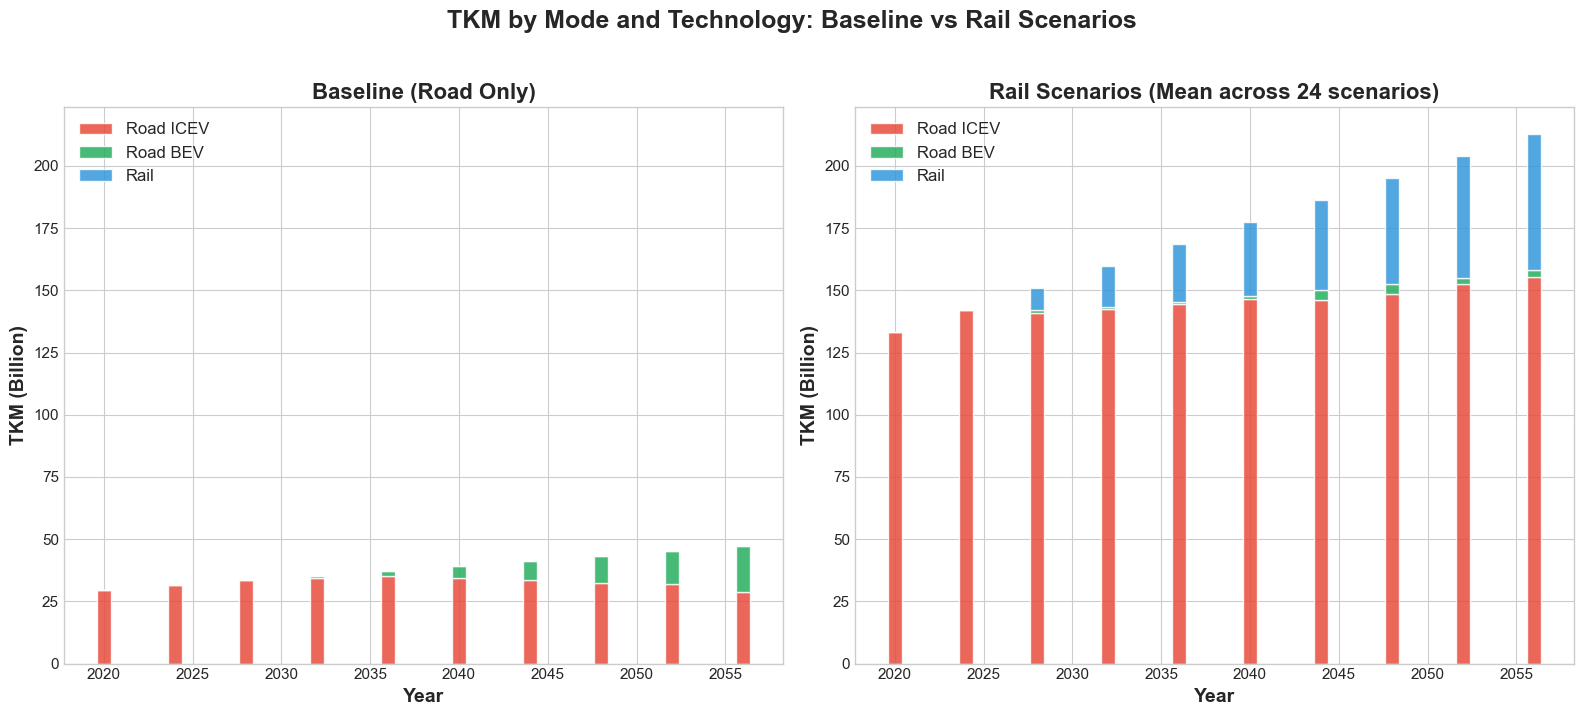

In [29]:
# Create stacked bar chart comparing baseline vs rail
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

years = sorted([y for y in rail_agg.keys() if 2020 <= y <= 2056])

# Colors
colors = {
    'Rail': '#3498db',      # Blue
    'Road_ICEV': '#e74c3c', # Red/Orange
    'Road_BEV': '#27ae60',  # Green
}

# Plot 1: Baseline (road-only)
ax = axes[0]
icev_vals = [baseline_agg[y]['Road_ICEV'][0]/1e9 for y in years]
bev_vals = [baseline_agg[y]['Road_BEV'][0]/1e9 for y in years]
rail_vals = [baseline_agg[y]['Rail'][0]/1e9 for y in years]  # Should be 0 for baseline

ax.bar(years, icev_vals, label='Road ICEV', color=colors['Road_ICEV'], alpha=0.85, edgecolor='white')
ax.bar(years, bev_vals, bottom=icev_vals, label='Road BEV', color=colors['Road_BEV'], alpha=0.85, edgecolor='white')
bottom_combined = [i + b for i, b in zip(icev_vals, bev_vals)]
ax.bar(years, rail_vals, bottom=bottom_combined, label='Rail', color=colors['Rail'], alpha=0.85, edgecolor='white')

ax.set_xlabel('Year', fontsize=14, fontweight='bold')
ax.set_ylabel('TKM (Billion)', fontsize=14, fontweight='bold')
ax.set_title('Baseline (Road Only)', fontsize=16, fontweight='bold')
ax.legend(loc='upper left', fontsize=12)
ax.tick_params(labelsize=11)

# Plot 2: Rail scenarios
ax = axes[1]
icev_vals = [rail_agg[y]['Road_ICEV'][0]/1e9 for y in years]
bev_vals = [rail_agg[y]['Road_BEV'][0]/1e9 for y in years]
rail_vals = [rail_agg[y]['Rail'][0]/1e9 for y in years]

ax.bar(years, icev_vals, label='Road ICEV', color=colors['Road_ICEV'], alpha=0.85, edgecolor='white')
ax.bar(years, bev_vals, bottom=icev_vals, label='Road BEV', color=colors['Road_BEV'], alpha=0.85, edgecolor='white')
bottom_combined = [i + b for i, b in zip(icev_vals, bev_vals)]
ax.bar(years, rail_vals, bottom=bottom_combined, label='Rail', color=colors['Rail'], alpha=0.85, edgecolor='white')

ax.set_xlabel('Year', fontsize=14, fontweight='bold')
ax.set_ylabel('TKM (Billion)', fontsize=14, fontweight='bold')
ax.set_title('Rail Scenarios (Mean across 24 scenarios)', fontsize=16, fontweight='bold')
ax.legend(loc='upper left', fontsize=12)
ax.tick_params(labelsize=11)

# Set same y-axis limits
max_y = max(axes[0].get_ylim()[1], axes[1].get_ylim()[1])
axes[0].set_ylim(0, max_y)
axes[1].set_ylim(0, max_y)

plt.suptitle('TKM by Mode and Technology: Baseline vs Rail Scenarios', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/tkm_by_mode_tech_comparison.pdf', bbox_inches='tight', dpi=150)
print("Saved: figures/tkm_by_mode_tech_comparison.pdf")
plt.show()

In [30]:
# Print summary statistics for a specific year
summary_year = 2040

print(f"\n{'='*80}")
print(f"TKM SUMMARY FOR YEAR {summary_year}")
print(f"{'='*80}")

print(f"\n{'Baseline (Road Only)':40s}")
print(f"  {'Mode/Tech':<20s} {'Mean (B tkm)':<15s} {'Std (B tkm)':<15s}")
print(f"  {'-'*50}")
for mode_tech in ['Rail', 'Road_ICEV', 'Road_BEV']:
    mean, std = baseline_agg[summary_year][mode_tech]
    print(f"  {mode_tech:<20s} {mean/1e9:<15.4f} {std/1e9:<15.4f}")
total_baseline = sum(baseline_agg[summary_year][mt][0] for mt in ['Rail', 'Road_ICEV', 'Road_BEV'])
print(f"  {'TOTAL':<20s} {total_baseline/1e9:<15.4f}")

print(f"\n{'Rail Scenarios':40s}")
print(f"  {'Mode/Tech':<20s} {'Mean (B tkm)':<15s} {'Std (B tkm)':<15s} {'Share (%)':<15s}")
print(f"  {'-'*65}")
total_rail = sum(rail_agg[summary_year][mt][0] for mt in ['Rail', 'Road_ICEV', 'Road_BEV'])
for mode_tech in ['Rail', 'Road_ICEV', 'Road_BEV']:
    mean, std = rail_agg[summary_year][mode_tech]
    share = (mean / total_rail * 100) if total_rail > 0 else 0
    print(f"  {mode_tech:<20s} {mean/1e9:<15.4f} {std/1e9:<15.4f} {share:<15.1f}")
print(f"  {'TOTAL':<20s} {total_rail/1e9:<15.4f}")

print(f"\n{'='*80}")


TKM SUMMARY FOR YEAR 2040

Baseline (Road Only)                    
  Mode/Tech            Mean (B tkm)    Std (B tkm)    
  --------------------------------------------------
  Rail                 0.0000          0.0000         
  Road_ICEV            34.4657         4.4955         
  Road_BEV             4.8190          4.4955         
  TOTAL                39.2847        

Rail Scenarios                          
  Mode/Tech            Mean (B tkm)    Std (B tkm)     Share (%)      
  -----------------------------------------------------------------
  Rail                 29.8933         0.0004          16.8           
  Road_ICEV            146.4179        0.0223          82.5           
  Road_BEV             1.1691          0.0227          0.7            
  TOTAL                177.4804       



## 5. Charged Energy by Latitude: Baseline vs Rail

In [36]:
# Charged energy by latitude - BEV only, comparing baseline vs rail
# Based on charging_constraint_comparison.ipynb approach

from scipy.ndimage import gaussian_filter1d

# Load geographic element data to get latitude for each node
geo_file = BASELINE_INPUT_DIR / "scenario_000" / "GeographicElement.yaml"
with open(geo_file, 'r') as f:
    geo_elements = yaml.safe_load(f)

# Build lookup: geo_id -> latitude (only nodes)
geo_id_to_lat = {}
for geo in geo_elements:
    if geo.get('type') == 'node' and 'coordinate_lat' in geo:
        geo_id_to_lat[geo['id']] = geo['coordinate_lat']

print(f"Loaded {len(geo_id_to_lat)} node locations with latitude data")

# Scaling factor for s values
S_SCALING_FACTOR = 1000

def calculate_bev_charging_by_latitude(s_dict, year):
    """
    Calculate BEV charging (GWh) aggregated by latitude for a specific year.
    s_dict key structure: (year, (product, odpair, path, geo_id), tv_id, (fuel, infra), gen)
    
    Only includes BEV charging (tv_id=1).
    """
    charging_by_lat = {}
    
    for key_str, energy_value_scaled in s_dict.items():
        try:
            key = eval(key_str) if isinstance(key_str, str) else key_str
            key_year = key[0]
            geo_id = key[1][3]  # geo_id is inside nested tuple at position 3
            tv_id = key[2]      # Vehicle technology: 0=ICEV, 1=BEV
            
            energy_value = float(energy_value_scaled) if isinstance(energy_value_scaled, str) else energy_value_scaled
            
            # Only include BEV charging (tv_id=1), skip year mismatch, skip zero/negative
            if key_year != year or tv_id != 1 or energy_value <= 0:
                continue
            
            if geo_id not in geo_id_to_lat:
                continue
            
            lat = geo_id_to_lat[geo_id]
            energy_kwh = energy_value * S_SCALING_FACTOR
            
            if lat not in charging_by_lat:
                charging_by_lat[lat] = 0.0
            charging_by_lat[lat] += energy_kwh
            
        except Exception as e:
            continue
    
    # Convert to GWh and return sorted list
    result = [(lat, kwh / 1e6) for lat, kwh in charging_by_lat.items()]
    result.sort(key=lambda x: x[0])
    return result

print("BEV charging by latitude function defined")

Loaded 81 node locations with latitude data
BEV charging by latitude function defined


In [37]:
# Aggregate BEV charging by latitude across all scenarios
analysis_year = 2040

def aggregate_charging_by_latitude(results_dir, scenarios, year):
    """
    Aggregate BEV charging by latitude across all scenarios.
    Returns average (lat, gwh) list.
    """
    all_lat_data = defaultdict(list)
    
    for scenario in scenarios:
        files = find_result_files(results_dir, scenario)
        if files and files['s_dict'].exists():
            s_dict = load_yaml_safe(files['s_dict'])
            lat_data = calculate_bev_charging_by_latitude(s_dict, year)
            
            for lat, gwh in lat_data:
                all_lat_data[lat].append(gwh)
    
    # Calculate average
    avg_data = [(lat, np.mean(gwh_list)) for lat, gwh_list in all_lat_data.items()]
    avg_data.sort(key=lambda x: x[0])
    return avg_data

print(f"Calculating BEV charging by latitude for year {analysis_year}...")

# Calculate for baseline (no rail) scenarios
baseline_lat_data = aggregate_charging_by_latitude(BASELINE_RESULTS_DIR, scenarios, analysis_year)
print(f"Baseline: {len(baseline_lat_data)} latitude points")

# Calculate for rail scenarios
rail_lat_data = aggregate_charging_by_latitude(RAIL_RESULTS_DIR, scenarios, analysis_year)
print(f"Rail: {len(rail_lat_data)} latitude points")

# Show totals
baseline_total = sum(x[1] for x in baseline_lat_data)
rail_total = sum(x[1] for x in rail_lat_data)
print(f"\nTotal BEV charging (year {analysis_year}):")
print(f"  Baseline (no rail): {baseline_total:.2f} GWh")
print(f"  Rail scenarios:     {rail_total:.2f} GWh")
print(f"  Difference:         {rail_total - baseline_total:.2f} GWh ({(rail_total - baseline_total) / baseline_total * 100:.1f}%)")

Calculating BEV charging by latitude for year 2040...
Baseline: 80 latitude points
Rail: 78 latitude points

Total BEV charging (year 2040):
  Baseline (no rail): 8.97 GWh
  Rail scenarios:     0.10 GWh
  Difference:         -8.87 GWh (-98.9%)


Saved: figures/bev_charging_by_latitude_rail_comparison.pdf


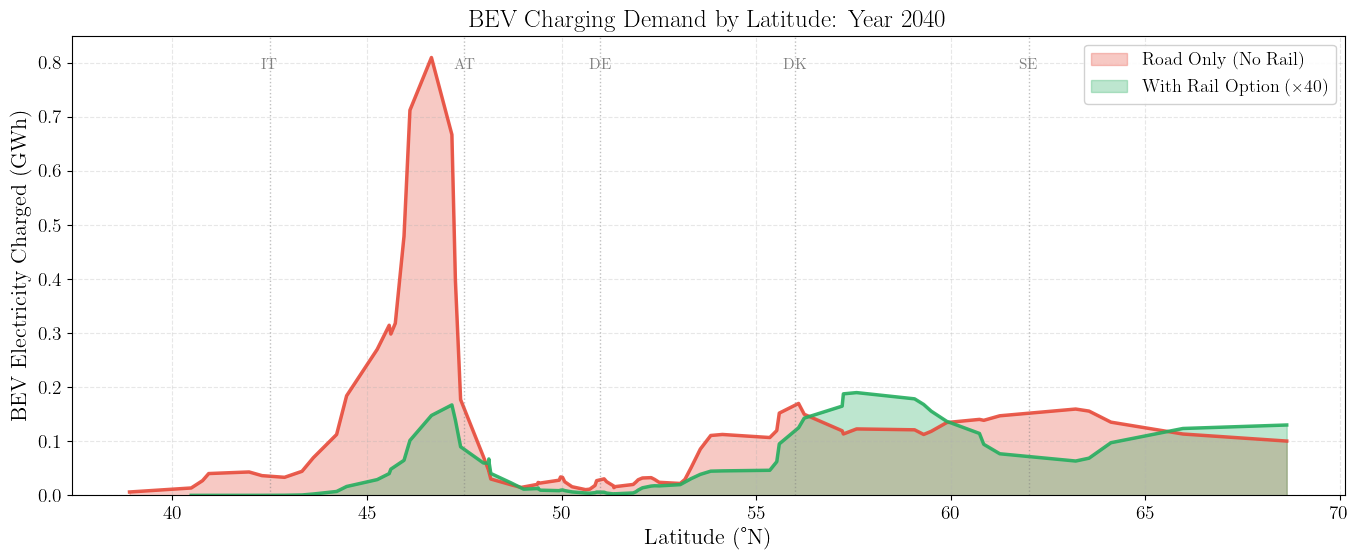

In [50]:
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    'font.serif': 'mathpazo',
    'font.size': 20,
    'axes.labelsize': 20
})
# Overlaid horizontal latitude comparison plot
def plot_latitude_comparison_overlaid(baseline_data, rail_data, year=2040, rail_scaling_factor=4.0):
    """
    Create overlaid area/line plot comparing BEV charging by latitude.
    Horizontal orientation: latitude on x-axis, GWh on y-axis.
    
    rail_scaling_factor: multiply rail GWh values by this factor to account for 
                         reduced road demand when rail is available
    """
    fig, ax = plt.subplots(figsize=(14, 6))
    
    # Colors
    color_baseline = '#E74C3C'  # Red - No Rail
    color_rail = '#27AE60'      # Green - With Rail
    
    def prepare_data(data, scaling_factor=1.0):
        if len(data) < 3:
            return None, None
        lats = np.array([x[0] for x in data])
        gwh = np.array([x[1] for x in data]) * scaling_factor
        sort_idx = np.argsort(lats)
        lat_sorted = lats[sort_idx]
        gwh_sorted = gwh[sort_idx]
        gwh_smoothed = gaussian_filter1d(gwh_sorted, sigma=1.5)
        return lat_sorted, gwh_smoothed
    
    # Prepare both datasets (rail scaled by factor)
    lat_base, gwh_base = prepare_data(baseline_data, scaling_factor=1.0)
    lat_rail, gwh_rail = prepare_data(rail_data, scaling_factor=rail_scaling_factor)
    
    if lat_base is None or lat_rail is None:
        ax.text(0.5, 0.5, 'Insufficient data', ha='center', va='center', transform=ax.transAxes)
        plt.show()
        return
    
    # Plot baseline (no rail) - area + line
    ax.fill_between(lat_base, 0, gwh_base, color=color_baseline, alpha=0.3, label='Road Only (No Rail)')
    ax.plot(lat_base, gwh_base, color=color_baseline, linewidth=2.5, alpha=0.9)
    
    # Plot rail scenarios - area + line (scaled)
    ax.fill_between(lat_rail, 0, gwh_rail, color=color_rail, alpha=0.3, 
                    label=f'With Rail Option (×{rail_scaling_factor:.0f})')
    ax.plot(lat_rail, gwh_rail, color=color_rail, linewidth=2.5, alpha=0.9)
    
    # Labels and formatting
    ax.set_xlabel('Latitude (°N)', fontsize=16, fontweight='bold')
    ax.set_ylabel('BEV Electricity Charged (GWh)', fontsize=16, fontweight='bold')
    ax.set_title(f'BEV Charging Demand by Latitude: Year {year} ', fontsize=18, fontweight='bold')
    ax.legend(loc='upper right', fontsize=13, framealpha=0.9)
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.tick_params(axis='both', labelsize=14)
    ax.set_ylim(bottom=0)
    
    # Add country reference annotations
    country_lats = {
        'IT': 42.5, 'AT': 47.5, 'DE': 51.0, 'DK': 56.0, 'SE': 62.0
    }
    ylim = ax.get_ylim()
    for country, lat in country_lats.items():
        ax.axvline(lat, color='gray', linestyle=':', alpha=0.5, linewidth=1)
        ax.text(lat, ylim[1] * 0.95, country, ha='center', va='top', fontsize=11, 
                color='gray', fontweight='bold')
    
    plt.tight_layout()
    plt.savefig('figures/bev_charging_by_latitude_rail_comparison.pdf', bbox_inches='tight', dpi=150)
    print("Saved: figures/bev_charging_by_latitude_rail_comparison.pdf")
    plt.show()

# Create the comparison plot with rail scaled by factor 4
plot_latitude_comparison_overlaid(baseline_lat_data, rail_lat_data, year=analysis_year, rail_scaling_factor=40.0)

In [41]:
# Relative factor analysis: Road-only vs With Rail option
# Compare total road demand (ICEV + BEV) between scenarios

print("="*80)
print("RELATIVE DEMAND FACTOR: Road Only vs With Rail Option")
print("="*80)

years = sorted([y for y in rail_agg.keys() if 2020 <= y <= 2056])

print(f"\n{'Year':<8} {'Road Only (B tkm)':<20} {'With Rail - Road (B tkm)':<25} {'With Rail - Rail (B tkm)':<25} {'Road Reduction Factor':<22} {'Rail Share (%)':<15}")
print("-" * 115)

for year in years:
    # Road-only scenario: total road demand
    baseline_road = (baseline_agg[year]['Road_ICEV'][0] + baseline_agg[year]['Road_BEV'][0]) / 1e9
    
    # Rail scenario: road demand and rail demand
    rail_road = (rail_agg[year]['Road_ICEV'][0] + rail_agg[year]['Road_BEV'][0]) / 1e9
    rail_rail = rail_agg[year]['Rail'][0] / 1e9
    rail_total = rail_road + rail_rail
    
    # Reduction factor: how much less road demand with rail option
    if baseline_road > 0:
        road_reduction_factor = rail_road / baseline_road
    else:
        road_reduction_factor = 1.0
    
    # Rail share
    if rail_total > 0:
        rail_share = (rail_rail / rail_total) * 100
    else:
        rail_share = 0
    
    print(f"{year:<8} {baseline_road:<20.4f} {rail_road:<25.4f} {rail_rail:<25.4f} {road_reduction_factor:<22.4f} {rail_share:<15.1f}")

print("-" * 115)

# Summary statistics
print(f"\n{'='*80}")
print("SUMMARY (Year 2040)")
print("="*80)

year = 2040
baseline_road_2040 = (baseline_agg[year]['Road_ICEV'][0] + baseline_agg[year]['Road_BEV'][0]) / 1e9
rail_road_2040 = (rail_agg[year]['Road_ICEV'][0] + rail_agg[year]['Road_BEV'][0]) / 1e9
rail_rail_2040 = rail_agg[year]['Rail'][0] / 1e9
rail_total_2040 = rail_road_2040 + rail_rail_2040

print(f"\nRoad-only scenario:")
print(f"  Total road demand: {baseline_road_2040:.4f} B tkm")

print(f"\nWith rail option:")
print(f"  Road demand:       {rail_road_2040:.4f} B tkm")
print(f"  Rail demand:       {rail_rail_2040:.4f} B tkm")
print(f"  Total demand:      {rail_total_2040:.4f} B tkm")

print(f"\nComparison:")
road_reduction = baseline_road_2040 - rail_road_2040
print(f"  Road demand reduction:    {road_reduction:.4f} B tkm ({road_reduction/baseline_road_2040*100:.1f}%)")
print(f"  Road reduction factor:    {rail_road_2040/baseline_road_2040:.4f} (road with rail / road only)")
print(f"  Rail modal share:         {rail_rail_2040/rail_total_2040*100:.1f}%")
print(f"  Demand absorbed by rail:  {rail_rail_2040:.4f} B tkm")

# Check if total demand is preserved
demand_diff = rail_total_2040 - baseline_road_2040
print(f"\n  Total demand difference:  {demand_diff:.4f} B tkm ({demand_diff/baseline_road_2040*100:.2f}%)")
print("="*80)

RELATIVE DEMAND FACTOR: Road Only vs With Rail Option

Year     Road Only (B tkm)    With Rail - Road (B tkm)  With Rail - Rail (B tkm)  Road Reduction Factor  Rail Share (%) 
-------------------------------------------------------------------------------------------------------------------
2020     29.4885              133.2229                  0.0000                    4.5178                 0.0            
2024     31.4477              142.0744                  0.0000                    4.5178                 0.0            
2028     33.4070              141.9097                  9.0162                    4.2479                 6.0            
2032     35.3662              143.4274                  16.3500                   4.0555                 10.2           
2036     37.3255              145.2406                  23.3882                   3.8912                 13.9           
2040     39.2847              147.5871                  29.8933                   3.7569               

## 6. Modal Split Over Time

Saved: figures/modal_split_evolution_rail.pdf


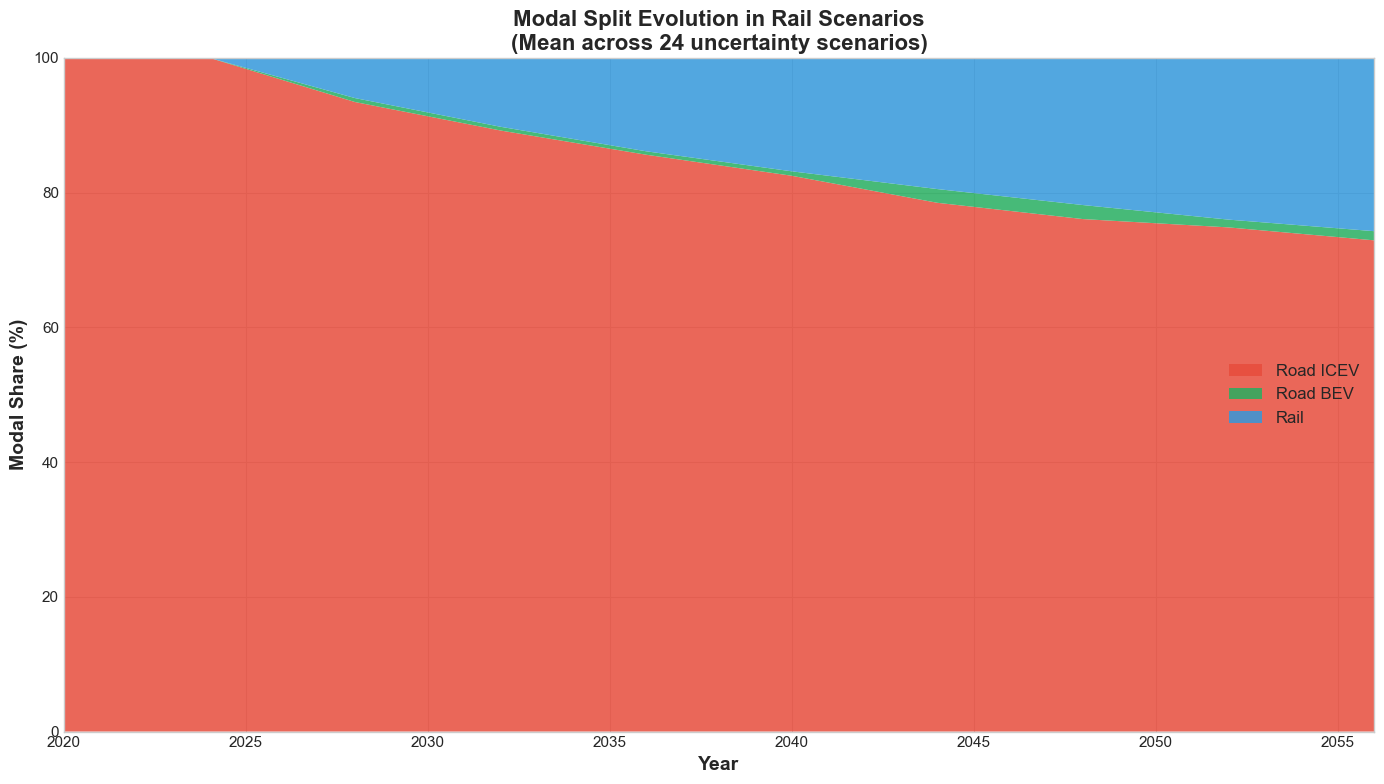

In [40]:
# Create modal split time series
fig, ax = plt.subplots(figsize=(14, 8))

years = sorted([y for y in rail_agg.keys() if 2020 <= y <= 2056])

# Calculate shares for rail scenarios
rail_share = []
road_icev_share = []
road_bev_share = []

for year in years:
    total = sum(rail_agg[year][mt][0] for mt in ['Rail', 'Road_ICEV', 'Road_BEV'])
    if total > 0:
        rail_share.append(rail_agg[year]['Rail'][0] / total * 100)
        road_icev_share.append(rail_agg[year]['Road_ICEV'][0] / total * 100)
        road_bev_share.append(rail_agg[year]['Road_BEV'][0] / total * 100)
    else:
        rail_share.append(0)
        road_icev_share.append(0)
        road_bev_share.append(0)

# Stacked area plot
ax.stackplot(years, road_icev_share, road_bev_share, rail_share,
             labels=['Road ICEV', 'Road BEV', 'Rail'],
             colors=[colors['Road_ICEV'], colors['Road_BEV'], colors['Rail']],
             alpha=0.85)

ax.set_xlabel('Year', fontsize=14, fontweight='bold')
ax.set_ylabel('Modal Share (%)', fontsize=14, fontweight='bold')
ax.set_title('Modal Split Evolution in Rail Scenarios\n(Mean across 24 uncertainty scenarios)', fontsize=16, fontweight='bold')
ax.legend(loc='center right', fontsize=12)
ax.set_ylim(0, 100)
ax.set_xlim(years[0], years[-1])
ax.tick_params(labelsize=11)

plt.tight_layout()
plt.savefig('figures/modal_split_evolution_rail.pdf', bbox_inches='tight', dpi=150)
print("Saved: figures/modal_split_evolution_rail.pdf")
plt.show()